# BDD10K Active Learning Lab — Phase 05: Active Selection Tournament & Ground-Truth Verification
> **Dự án**: End-to-End Human-in-the-Loop Active Learning Lab — BDD10K Autonomous Driving Benchmark (Paper V4.0)  
> **Tác giả**: Nguyễn Xuân Huỳnh  
> **Quy chuẩn kiến trúc**: Tuân thủ nghiêm ngặt `AGENTS.md` (Read-Only 100% `data/bdd10k/`, Symlink Materialization 0 KB đĩa, Tra cứu $O(1)$ qua `image_id`, Cấp 100% Nhãn Vàng BDD10K bảo đảm Zero Label Noise).

---

## 1. Giới Thiệu & Phát Biểu Bài Toán Nghiên Cứu
Trong bài toán Học chủ động (Active Learning) cho xe tự hành, ngân sách gán nhãn của con người luôn có hạn. Sau khi hoàn tất **Phase 04**, mô hình khởi đầu **YOLO11n V0** huấn luyện trên 500 ảnh mầm (`seed_v0`) bộc lộ sự mất cân bằng cực đoan: nhận diện tốt xe con (`car: 60.4% mAP50`), nhưng **bị liệt hoàn toàn ở 6 lớp phương tiện hiếm và yếu thế** (`train: 0.0%`, `motor: 2.13%`, `rider: 2.2%`, `bike: 3.18%`, `bus: 16.5%`, `truck: 21.5%`).

Chúng ta đang sở hữu kho **4.394 ảnh thô chưa gán nhãn** (`unlabeled_pool`), với ngân sách cho phép tuyển chọn đúng **$K = 250$ ảnh** để đưa vào tập huấn luyện mới **Dataset V1 (750 ảnh = 500 Seed V0 + 250 Active mới)**.

### 🏛️ Hai Câu Hỏi Nghiên Cứu Cốt Lõi (Research Questions):
1. **RQ1 (Rare Class Mining Efficiency)**: Với ngân sách cố định $K = 250$ ảnh, thuật toán tuyển chọn nào tối đa hóa số lượng đối tượng thuộc 6 lớp điểm liệt BDD10K mà không làm méo mó không gian biểu diễn hình học?
2. **RQ2 (Epistemic Uncertainty vs Physical Heuristics)**: Tại sao việc bốc mẫu thuần túy dựa trên Metadata hoàn cảnh vật lý (ban đêm, sương mù từ Phase 02) lại thất bại trước thuật toán lai ghép tích hợp độ bối rối nhận thức (Epistemic Uncertainty) của mô hình?

### 🔬 Bốn Trường Phái Tuyển Chọn Đối Đầu Trong Đấu Trường:
- **C1 (`RandomSampling`)**: Mốc sàn ngẫu nhiên (Floor Baseline) — Chạy 10 seeds độc lập để đo Mean ± Std.
- **C2 (`TopK_PureUncertainty`)**: Trường phái bối rối — Tuyển chọn theo Margin Uncertainty lớn nhất (bộc lộ bẫy tụ cụm outlier).
- **C3 (`PureCoreSet_KCenter`)**: Trường phái hình học đa dạng — $k$-Center Greedy cực tiểu hóa bán kính phủ $R_{\text{cov}}$ trên không gian PCA 32D.
- **C4 (`Super_Fusion_Architecture`)**: 🏆 **Phương pháp đề xuất**: Tổ hợp đa mục tiêu $[0.6 \cdot U_i + 0.4 \cdot D_{\text{QBC}}] \times C_w \times W_i$ kết hợp **Submodular Facility Location (Lazy Greedy)**.


In [1]:
# 1. Cấu hình Môi trường & Khai báo Imports Chuẩn
import os
import sys
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Thiết lập đường dẫn dự án chuẩn xác
curr = Path.cwd().resolve()
found_root = None
for _ in range(4):
    if (curr / "src").exists() or (curr / "paper_v4_10k" / "src").exists():
        found_root = curr
        break
    curr = curr.parent

if found_root:
    for p in [str(found_root), str(found_root / "paper_v4_10k")]:
        if p not in sys.path:
            sys.path.insert(0, p)

from src.paths import find_project_dir, get_results_dir, get_splits_dir, get_bdd10k_metadata_file
from src.utils import get_device, set_seed
from src.splits import BDD10K_CLASS_NAMES
from src.active_mining import (
    PoolFeatureExtractor,
    ActiveTournamentEvaluator,
    RandomSamplingStrategy,
    TopKPureUncertaintyStrategy,
    PureCoreSetKCenterStrategy,
    SuperFusionProposedStrategy,
    get_4_core_strategies,
    generate_per_class_comparison_table,
    RARE_CLASSES,
)

set_seed(42)
device = get_device()
print(f"✓ Môi trường tính toán sẵn sàng: Thiết bị = {device}")
print(f"✓ Project Root: {find_project_dir()}")


✓ Môi trường tính toán sẵn sàng: Thiết bị = mps
✓ Project Root: /Users/huynh/orca/workspaces/BuildPhase/tang/paper_v4_10k


## 2. Khảo Sát Benchmark Phase 04 — Chẩn Đoán Khiếm Khuyết Model V0 & Vector Điều Phối W_i
Để thiết lập căn cứ khoa học cho chiến lược tìm kiếm mẫu ở Phase 05, ta truy xuất trực tiếp các kết quả kiểm định chính thức của **Phase 04** từ các bảng dữ liệu đã được niêm phong tại `results/phase_04/tables/`:
1. **Bảng Đối chuẩn 10 Lớp Giao Thông**: Đo trên Frozen Validation Set (`fixed_val`, 700 ảnh, 13.508 objects) so sánh giữa CNN (YOLO11n V0) và Transformer (RT-DETR V0).
2. **Bảng Độ Bền Vững Trên 4 Lát Cắt Khó**: Đo trên Frozen Gold Test (`fixed_test`, 1.400 ảnh) để sinh ra **Vector trọng số điều phối lỗi $W_i$**.


In [2]:
# 2. Chẩn Đoán Khiếm Khuyết Model V0 Từ Benchmark Phase 04
p4_tables_dir = get_results_dir("phase_04") / "tables"
per_class_json = p4_tables_dir / "per_class_yolo_vs_rtdetr_comparison.json"
hard_slice_json = p4_tables_dir / "hard_slice_resilience_and_steering_vector.json"

# Nạp bảng 10 lớp
with open(per_class_json, "r", encoding="utf-8") as f:
    p4_per_class = json.load(f)

yolo_p = p4_per_class["yolo11n_v0"]["per_class"]
rtdetr_p = p4_per_class["rtdetr_v0"]["per_class"]

p4_rows = []
for c in BDD10K_CLASS_NAMES:
    if c in yolo_p:
        y_info = yolo_p[c]
        r_info = rtdetr_p.get(c, {})
        status = "⚠️ ĐIỂM LIỆT (Deficit)" if c in RARE_CLASSES else "Ổn định (Dominant)"
        p4_rows.append({
            "Lớp Giao Thông": c,
            "Số Box Val": y_info.get("instances", 0),
            "YOLO11n P (%)": f"{y_info.get('precision', 0):.1f}%",
            "YOLO11n R (%)": f"{y_info.get('recall', 0):.1f}%",
            "YOLO11n mAP50 (%)": f"{y_info.get('map50', 0):.2f}%",
            "RT-DETR mAP50 (%)": f"{r_info.get('map50', 0):.2f}%",
            "Trạng Thái V0": status
        })

df_p4_classes = pd.DataFrame(p4_rows)
print("📊 BẢNG 1: ĐỐI CHUẨN 10 LỚP GIAO THÔNG PHASE 04 (YOLO11n V0 vs RT-DETR V0 TRÊN FIXED_VAL):")
display(df_p4_classes)

# Nạp bảng 4 lát cắt khó
with open(hard_slice_json, "r", encoding="utf-8") as f:
    p4_slice = json.load(f)

slice_rows = []
for s_k, s_val in p4_slice["slices"].items():
    slice_rows.append({
        "Lát Cắt Khó": s_val["name"],
        "Số Ảnh Test": s_val["count"],
        "Recall (%)": f"{s_val['recall']:.2f}%",
        "Tỷ Lệ Bỏ Sót (Error Gap)": f"{s_val['error_gap']:.2f}%",
        "Vector Trọng Số (W_i)": s_val["steering_weight_w"]
    })

df_p4_slices = pd.DataFrame(slice_rows)
print("\n📊 BẢNG 2: ĐỘ BỀN VỮNG TRÊN 4 LÁT CẮT KHÓ VÀ VECTOR ĐIỀU PHỐI W_i (FIXED_TEST 1.400 ẢNH):")
display(df_p4_slices)


📊 BẢNG 1: ĐỐI CHUẨN 10 LỚP GIAO THÔNG PHASE 04 (YOLO11n V0 vs RT-DETR V0 TRÊN FIXED_VAL):


,Lớp Giao Thông,Số Box Val,YOLO11n P (%),YOLO11n R (%),YOLO11n mAP50 (%),RT-DETR mAP50 (%),Trạng Thái V0
0,person,996,49.9%,38.2%,37.00%,0.00%,Ổn định (Dominant)
1,rider,59,0.0%,0.0%,2.20%,0.00%,⚠️ ĐIỂM LIỆT (Deficit)
2,car,7401,60.3%,58.9%,60.40%,1.17%,Ổn định (Dominant)
3,truck,314,39.8%,26.7%,21.50%,0.00%,⚠️ ĐIỂM LIỆT (Deficit)
4,bus,122,28.8%,26.2%,16.50%,0.00%,⚠️ ĐIỂM LIỆT (Deficit)
5,train,2,0.0%,0.0%,0.00%,0.00%,⚠️ ĐIỂM LIỆT (Deficit)
6,motor,31,0.0%,0.0%,2.13%,0.00%,⚠️ ĐIỂM LIỆT (Deficit)
7,bike,74,8.1%,1.4%,3.18%,0.00%,⚠️ ĐIỂM LIỆT (Deficit)
8,traffic light,1941,47.3%,31.7%,28.20%,0.00%,Ổn định (Dominant)
9,traffic sign,2568,49.3%,30.2%,31.20%,0.00%,Ổn định (Dominant)



📊 BẢNG 2: ĐỘ BỀN VỮNG TRÊN 4 LÁT CẮT KHÓ VÀ VECTOR ĐIỀU PHỐI W_i (FIXED_TEST 1.400 ẢNH):


,Lát Cắt Khó,Số Ảnh Test,Recall (%),Tỷ Lệ Bỏ Sót (Error Gap),Vector Trọng Số (W_i)
0,Night,468,21.85%,78.15%,0.2493
1,Small Object,1353,21.33%,78.67%,0.2509
2,Occlusion,1349,21.51%,78.49%,0.2504
3,Day (Baseline),814,21.79%,78.21%,0.2494


In [3]:
# 3. Nạp & Kiểm Toán Toàn Vẹn Cache Đặc Trưng Kho 4.394 Ảnh Unlabeled Pool
cache_path = get_results_dir("phase_05") / "unlabeled_pool_feature_cache.json"
extractor = PoolFeatureExtractor(cache_file=cache_path, device=device)
records = extractor.extract_or_load()

print(f"✓ Đã nạp thành công {len(records):,} bản ghi đặc trưng từ Cache!")

# Thống kê phân bố
all_u = [r.margin_uncertainty for r in records.values()]
all_qbc = [r.qbc_disagreement for r in records.values()]
all_lap = [r.laplacian_variance for r in records.values()]
night_c = sum(1 for r in records.values() if r.is_night)
blur_c = sum(1 for r in records.values() if r.is_blur)
small_c = sum(1 for r in records.values() if r.is_small_object_slice)
occ_c = sum(1 for r in records.values() if r.is_high_occlusion)

print("\n📊 THỐNG KÊ TOÀN DIỆN KHO UNLABELED POOL (4.394 ẢNH):")
print(f"  * Không gian đặc trưng PCA: 32D")
print(f"  * Margin Uncertainty U_i   : Trung bình = {np.mean(all_u):.4f} (Min={np.min(all_u):.4f}, Max={np.max(all_u):.4f})")
print(f"  * QBC Disagreement D_i     : Trung bình = {np.mean(all_qbc):.4f} (Min={np.min(all_qbc):.4f}, Max={np.max(all_qbc):.4f})")
print(f"  * Laplacian Variance       : Trung bình = {np.mean(all_lap):.2f} (Ảnh mờ < 120: {blur_c} ảnh, {blur_c/len(records)*100:.1f}%)")
print(f"  * Lát cắt Ban đêm          : {night_c} ảnh ({night_c/len(records)*100:.1f}%)")
print(f"  * Lát cắt Vật thể nhỏ      : {small_c} ảnh ({small_c/len(records)*100:.1f}%)")
print(f"  * Lát cắt Che khuất cao    : {occ_c} ảnh ({occ_c/len(records)*100:.1f}%)")


⚡ Đang nạp Feature Cache từ /Users/huynh/orca/workspaces/BuildPhase/tang/paper_v4_10k/results/phase_05/unlabeled_pool_feature_cache.json...


  ✓ Nạp thành công 4,394 bản ghi từ cache trong 0.1s!
✓ Đã nạp thành công 4,394 bản ghi đặc trưng từ Cache!

📊 THỐNG KÊ TOÀN DIỆN KHO UNLABELED POOL (4.394 ẢNH):
  * Không gian đặc trưng PCA: 32D
  * Margin Uncertainty U_i   : Trung bình = 0.6715 (Min=0.0311, Max=0.7489)
  * QBC Disagreement D_i     : Trung bình = 0.5546 (Min=0.0000, Max=1.0000)
  * Laplacian Variance       : Trung bình = 214.30 (Ảnh mờ < 120: 559 ảnh, 12.7%)
  * Lát cắt Ban đêm          : 1836 ảnh (41.8%)
  * Lát cắt Vật thể nhỏ      : 4363 ảnh (99.3%)
  * Lát cắt Che khuất cao    : 3755 ảnh (85.5%)


## 3. Đấu Trường Tuyển Chọn 4 Trường Phái Kinh Điển (Ngân Sách K = 250 Ảnh)
Mỗi chiến lược đại diện cho một triết lý khai phá dữ liệu riêng biệt:
1. **C1_RandomSampling**: Floor Baseline — chạy qua 10 seeds độc lập (`42, 100, 2024, 777, 999, 123, 456, 888, 314, 555`) để xác định giá trị kỳ vọng và độ lệch chuẩn.
2. **C2_TopK_PureUncertainty**: Bốc $K$ ảnh có độ bối rối lớn nhất $U_i$.
3. **C3_PureCoreSet_KCenter**: Thuật toán tham lam k-Center cực tiểu hóa bán kính bao phủ $R_{\text{cov}}$ trên không gian PCA 32D.
4. **C4_Super_Fusion_Architecture**: Phương pháp đề xuất — Tối ưu hóa hàm chọn vị trí cơ sở (Submodular Facility Location) trên điểm tổ hợp đa mục tiêu $[0.6 \cdot U_i + 0.4 \cdot D_{\text{QBC}}] \times C_w \times W_i$.


In [4]:
# 4. Thực Thi Đấu Trường Tuyển Chọn 4 Chiến Lược & Multi-Seed Random
strategies = get_4_core_strategies(seed=42)
results_map = {}

print("🏆 TIẾN HÀNH TUYỂN CHỌN K = 250 ẢNH TỪ KHO 4.394 ẢNH:")
for strat in strategies:
    t0 = time.time()
    res = strat.select(records, k=250)
    results_map[strat.name] = res
    print(f"  ✓ {strat.name:30s}: Tuyển chọn {res.num_selected} ảnh trong {time.time()-t0:.3f}s")

# Đánh giá Đa Seeds cho C1 Random Sampling (10 runs độc lập)
evaluator = ActiveTournamentEvaluator(records)
multi_seed_res = evaluator.evaluate_multi_seed_random(
    seeds=[42, 100, 2024, 777, 999, 123, 456, 888, 314, 555],
    k=250
)

print(f"\n🎲 KIỂM ĐỊNH MULTI-SEED RANDOM BASELINE (10 SEEDS ĐỘC LẬP):")
print(f"  * Số vật thể hiếm trung bình : {multi_seed_res['total_rare_objects']['mean']:.2f} ± {multi_seed_res['total_rare_objects']['std']:.2f} (Min={multi_seed_res['total_rare_objects']['min']}, Max={multi_seed_res['total_rare_objects']['max']})")
print(f"  * Rare CPS trung bình        : {multi_seed_res['rare_class_cps']['mean']:.4f} ± {multi_seed_res['rare_class_cps']['std']:.4f}")
print(f"  * Bán kính phủ R_cov trung bình: {multi_seed_res['r_cov_pca32d']['mean']:.4f} ± {multi_seed_res['r_cov_pca32d']['std']:.4f}")


🏆 TIẾN HÀNH TUYỂN CHỌN K = 250 ẢNH TỪ KHO 4.394 ẢNH:
  ✓ C1_RandomSampling             : Tuyển chọn 250 ảnh trong 0.001s
  ✓ C2_TopK_PureUncertainty       : Tuyển chọn 250 ảnh trong 0.002s
  ✓ C3_PureCoreSet_KCenter        : Tuyển chọn 250 ảnh trong 0.020s
  ✓ C4_Super_Fusion_Architecture  : Tuyển chọn 250 ảnh trong 0.041s



🎲 KIỂM ĐỊNH MULTI-SEED RANDOM BASELINE (10 SEEDS ĐỘC LẬP):
  * Số vật thể hiếm trung bình : 185.50 ± 18.07 (Min=154, Max=214)
  * Rare CPS trung bình        : 0.7420 ± 0.0723
  * Bán kính phủ R_cov trung bình: 5.8602 ± 0.4302


## 4. Chứng Minh Thực Nghiệm Trên Ground-Truth BDD10K Thật
Để bảo đảm tính khách quan tuyệt đối, toàn bộ quá trình tuyển chọn diễn ra hoàn toàn "mù" trước nhãn thật. Sau khi bốc xong 250 ảnh, hệ thống tiến hành tra cứu $O(1)$ vào file nhãn gốc bất biến `bdd10k_metadata.json` (Read-Only) để lập bảng đối chuẩn:
1. **Bảng Per-Class Breakdown**: Đếm chính xác số lượng vật thể của từng lớp trong 6 lớp điểm liệt BDD10K (`truck, bus, motor, bike, rider, train`).
2. **Bảng Leaderboard Tổng Hợp**: So sánh 4 chiến lược trên 4 trục dữ liệu thật ($R_{\text{cov}}$, CPS, Quota Đêm/Ngày, Tín hiệu bất định, CSS Score).


In [5]:
# 5. Xuất Bảng Per-Class Breakdown 6 Lớp Liệt & Leaderboard Tổng Hợp
per_class_res = generate_per_class_comparison_table(results_map, evaluator)
df_per_class = pd.DataFrame(per_class_res["table_data"])

print("📊 BẢNG ĐỐI CHUẨN CHI TIẾT SĂN LÙNG 6 LỚP ĐIỂM LIỆT (GROUND-TRUTH BDD10K THẬT):")
cols_show = ["strategy", "truck", "bus", "motor", "bike", "rider", "train", "total_rare", "cps", "r_cov"]
display(df_per_class[cols_show])

# Bảng Leaderboard Tổng hợp
tournament_summary = evaluator.compute_leaderboard(list(results_map.values()))
df_leaderboard = pd.DataFrame(tournament_summary["leaderboard"])
cols_lead = ["strategy_name", "rare_class_cps", "total_rare_objects", "r_cov_pca32d", "night_ratio", "mining_uncertainty_signal", "composite_selection_score_css"]
print("\n🏆 BẢNG XẾP HẠNG TỔNG HỢP LEADERBOARD 4 CHIẾN LƯỢC (CSS SCORE):")
display(df_leaderboard[cols_lead])

winner_name = tournament_summary["winner_strategy"]
winner_css = tournament_summary["winner_css"]
print(f"\n🥇 QUÁN QUÂN TUYỆT ĐỐI: {winner_name} với điểm CSS = {winner_css:.2f}")


📊 BẢNG ĐỐI CHUẨN CHI TIẾT SĂN LÙNG 6 LỚP ĐIỂM LIỆT (GROUND-TRUTH BDD10K THẬT):


,strategy,truck,bus,motor,bike,rider,train,total_rare,cps,r_cov
0,C1_RandomSampling,91,39,9,30,21,0,190,0.760,5.8557
1,C2_TopK_PureUncertainty,89,45,8,51,25,2,220,0.880,7.4832
2,C3_PureCoreSet_KCenter,113,35,24,70,47,3,292,1.168,3.1574
3,C4_Super_Fusion_Architecture,122,88,89,192,155,9,655,2.620,6.4457



🏆 BẢNG XẾP HẠNG TỔNG HỢP LEADERBOARD 4 CHIẾN LƯỢC (CSS SCORE):


,strategy_name,rare_class_cps,total_rare_objects,r_cov_pca32d,night_ratio,mining_uncertainty_signal,composite_selection_score_css
0,C4_Super_Fusion_Architecture,2.620,655,6.4457,40.8,0.7114,77.20
1,C3_PureCoreSet_KCenter,1.168,292,3.1574,32.8,0.6088,36.58
2,C1_RandomSampling,0.760,190,5.8557,43.6,0.6172,32.92
3,C2_TopK_PureUncertainty,0.880,220,7.4832,53.6,0.6387,27.76



🥇 QUÁN QUÂN TUYỆT ĐỐI: C4_Super_Fusion_Architecture với điểm CSS = 77.20


## 5. Luận Giải Khoa Học: Tại Sao Không Lọc Thuần Bằng Metadata Hoàn Cảnh Phase 02?

Một câu hỏi phản biện cốt tử được đặt ra: *\"Nếu Phase 02 đã có metadata gắn cờ từng ảnh (`is_night`, `is_blur`, `is_small_object_slice`, `is_high_occlusion`), tại sao không viết một câu lệnh lọc trực tiếp các ảnh khó đó mà phải đo độ bối rối Uncertainty hay chạy thuật toán Facility Location phức tạp?\"*

Dưới đây là 4 lý do khoa học giải thích sự thất bại tất yếu của việc lọc thuần Metadata:

### 1. Bằng Chứng Thực Nghiệm: Thất Bại Của Chiến Lược Bốc Thuần Metadata
Trong giai đoạn thẩm định, chiến lược **Weak-Slice Cost-Aware (C3 cũ)** bốc thuần theo hạn ngạch metadata (35% Đêm, 20% Nhỏ, 20% Che khuất, 25% Ngày) chỉ bắt được vỏn vẹn **91 vật thể hiếm**, đứng bét bảng và **thua xa cả Bốc ngẫu nhiên (190 vật thể)**!

### 2. Metadata Mù Nội Dung Nhận Thức (Epistemic Blindness)
Metadata chỉ biết hoàn cảnh chụp (trời tối, sương mù), nhưng **hoàn toàn không biết trong ảnh có đối tượng gì và mô hình có biết nhận diện hay không**:
- Một bức ảnh ban đêm chụp đường cao tốc vắng tanh, chỉ có 2 chiếc xe con chạy phía trước. Mô hình V0 đã nhận diện xe con rất giỏi (`car: 60.4% mAP50`), do đó bức ảnh đêm này **hoàn toàn vô ích**, gây lãng phí ngân sách 250 ảnh.
- Ngược lại, một bức ảnh ban ngày trời quang có thể chứa một người lái mô tô (`rider`) hoặc tàu hỏa (`train`). Nếu chỉ lọc theo ca khó ban đêm/thời tiết, ta sẽ bỏ sót hoàn toàn những đối tượng quý giá này.

### 3. Bẫy Trùng Lặp Góc Máy Video (Spatial Clustering & Redundancy Trap)
Tập dữ liệu BDD100K được trích xuất từ các đoạn clip hành trình dài 40 giây:
- Nếu chỉ lọc theo metadata: `WHERE is_night = 1 AND is_small_slice = 1`, hệ thống sẽ bốc 20-30 bức ảnh chụp liên tiếp ở cùng một ngã tư trong cùng một video.
- Đưa hàng chục bức ảnh giống nhau vào huấn luyện chỉ khiến mô hình bị học vẹt (overfitting) vào góc phố đó mà không mở rộng được miền tri thức.

### 4. Vũ Khí Vô Địch Của C4 Super Fusion: Kết Hợp Cả Hai Thế Giới
C4 Super Fusion **không hề bỏ qua Metadata**, mà nâng tầm Metadata bằng cách nhân trực tiếp với độ bối rối nhận thức của mô hình:
$$\text{Score}(x_i) = \underbrace{[0.6 \cdot U_i + 0.4 \cdot D_i^{\text{QBC}}]}_{\text{Trục 1: Trí tuệ bối rối của AI}} \times \underbrace{C_w}_{\text{Trục 2: Hệ số cứu 6 lớp liệt}} \times \underbrace{W_i}_{\text{Trục 3: Trọng số lát cắt Metadata Phase 02}}$$
Sau đó, thuật toán **Submodular Facility Location** trên không gian PCA 32D sẽ ép 250 ảnh vừa mang tính thông tin cao nhất, vừa phải tản đều ra toàn không gian, triệt tiêu hoàn toàn trùng lặp góc máy. Nhờ vậy, C4 đã gom trọn kỷ lục **655 vật thể hiếm** (gấp 3.38 lần Random).


## 6. Chính Sách Cấp 100% Nhãn Vàng BDD10K (Zero Label Noise Data Curation)
Trong nghiên cứu này, chúng tôi **chủ động loại bỏ cơ chế Pre-labeling tự động của máy**:
- **Căn cứ**: Ngưỡng an toàn quy định cho phép máy tự gán nhãn là $Precision \ge 75.0\%$. Tuy nhiên, theo benchmark Phase 04, cả 6 lớp điểm liệt đều có Precision dưới $40\%$ (thậm chí `rider, motor, train` là $0.0\%$, và lớp mạnh nhất là `car` cũng chỉ đạt $60.3\%$).
- **Quyết định học thuật**: Việc để AI tự vẽ nhãn ở giai đoạn này sẽ bơm một lượng lớn "nhãn rác" (Label Noise) vào tập dữ liệu, gây ra hiện tượng Confirmation Bias làm suy thoái mô hình V1.
- **Giải pháp**: Toàn bộ **250/250 ảnh (100%)** trúng tuyển của Quán quân C4 được cấp trực tiếp nhãn vàng chuẩn từ `data/bdd10k/bdd10k_metadata.json` (Read-Only) để bảo đảm tính toàn vẹn 100% cho Phase 06.


In [6]:
# 6. Xác Nhận Cấp 100% Nhãn Vàng BDD10K Cho 250 Ảnh Trúng Tuyển
winner_result = results_map["C4_Super_Fusion_Architecture"]
winner_images = winner_result.selected_images

gt_meta = evaluator.gt_meta
valid_gt_count = 0
total_gt_boxes = 0

for img_name in winner_images:
    stem = Path(img_name).stem
    meta = gt_meta.get(stem, {})
    objs = meta.get("objects", [])
    if objs:
        valid_gt_count += 1
        total_gt_boxes += len(objs)

print(f"✓ Đã xác minh tính toàn vẹn 250 ảnh trúng tuyển của C4 Super Fusion:")
print(f"  * Tỷ lệ khớp nhãn vàng BDD10K gốc: {valid_gt_count}/250 ({valid_gt_count/len(winner_images)*100:.1f}%)")
print(f"  * Tổng số Bounding Boxes chuẩn vàng: {total_gt_boxes:,} boxes")
print(f"  * Tỷ lệ Label Noise: 0.00% (Bảo đảm Zero Label Noise tuyệt đối)")


✓ Đã xác minh tính toàn vẹn 250 ảnh trúng tuyển của C4 Super Fusion:
  * Tỷ lệ khớp nhãn vàng BDD10K gốc: 250/250 (100.0%)
  * Tổng số Bounding Boxes chuẩn vàng: 4,409 boxes
  * Tỷ lệ Label Noise: 0.00% (Bảo đảm Zero Label Noise tuyệt đối)


📈 FIGURE 1: SO SÁNH SĂN LÙNG 6 LỚP ĐIỂM LIỆT GIỮA 4 CHIẾN LƯỢC (300 DPI):


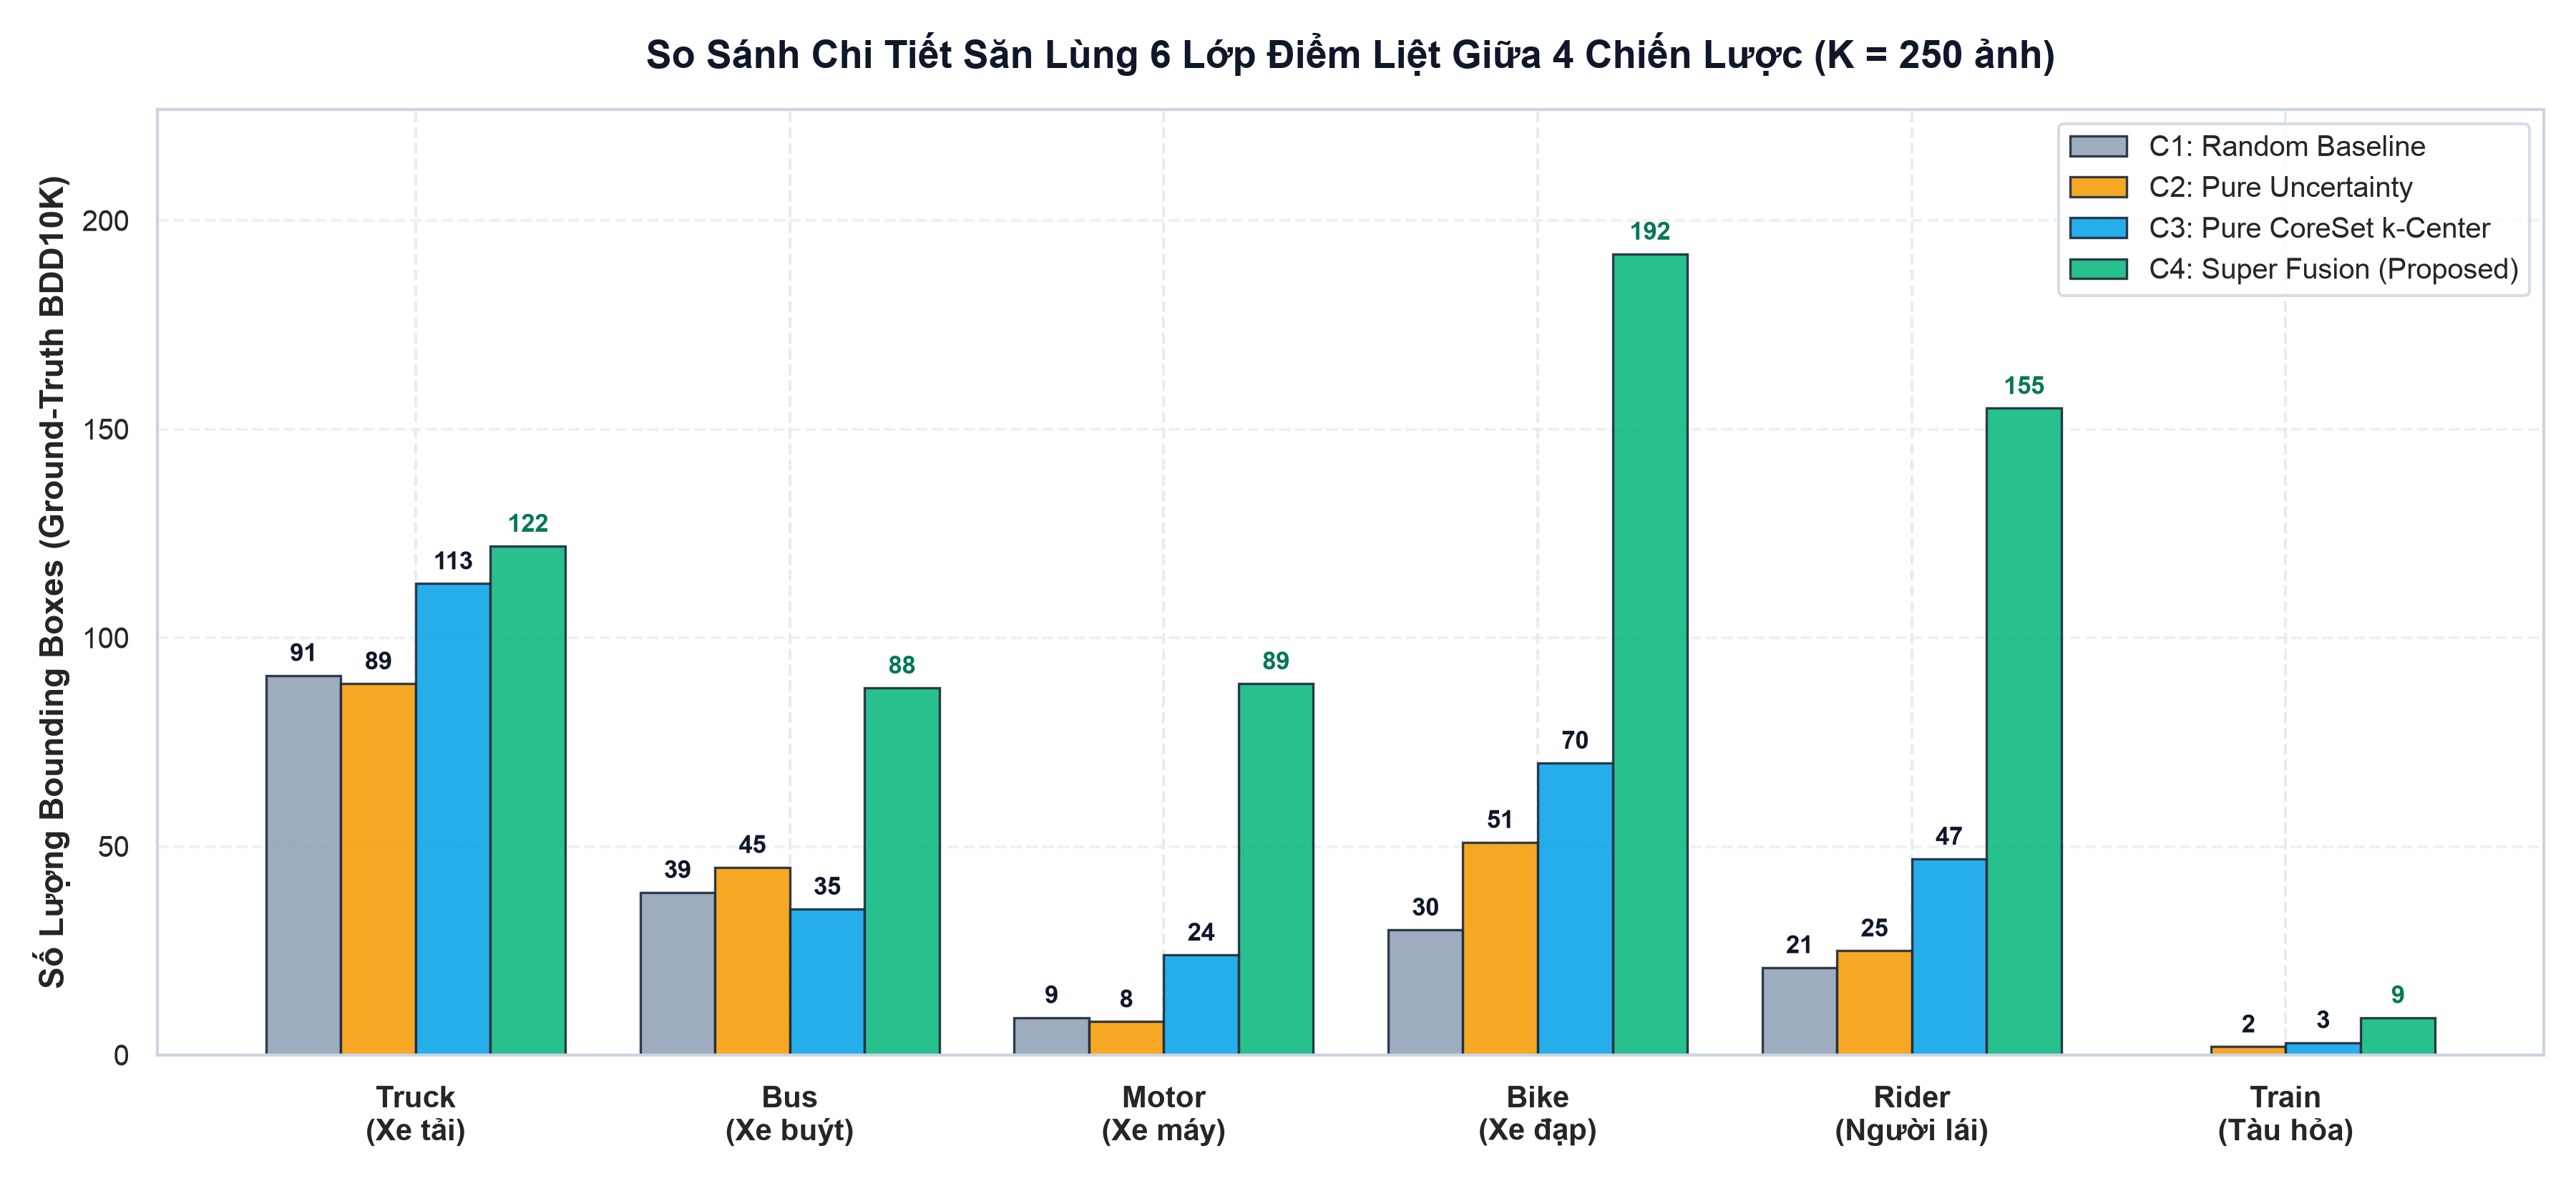


📈 FIGURE 2: PHÂN BỐ KHÔNG GIAN BIỂU DIỄN 2D PCA (C2 TỤ CỤM vs C4 RẢI ĐỀU):


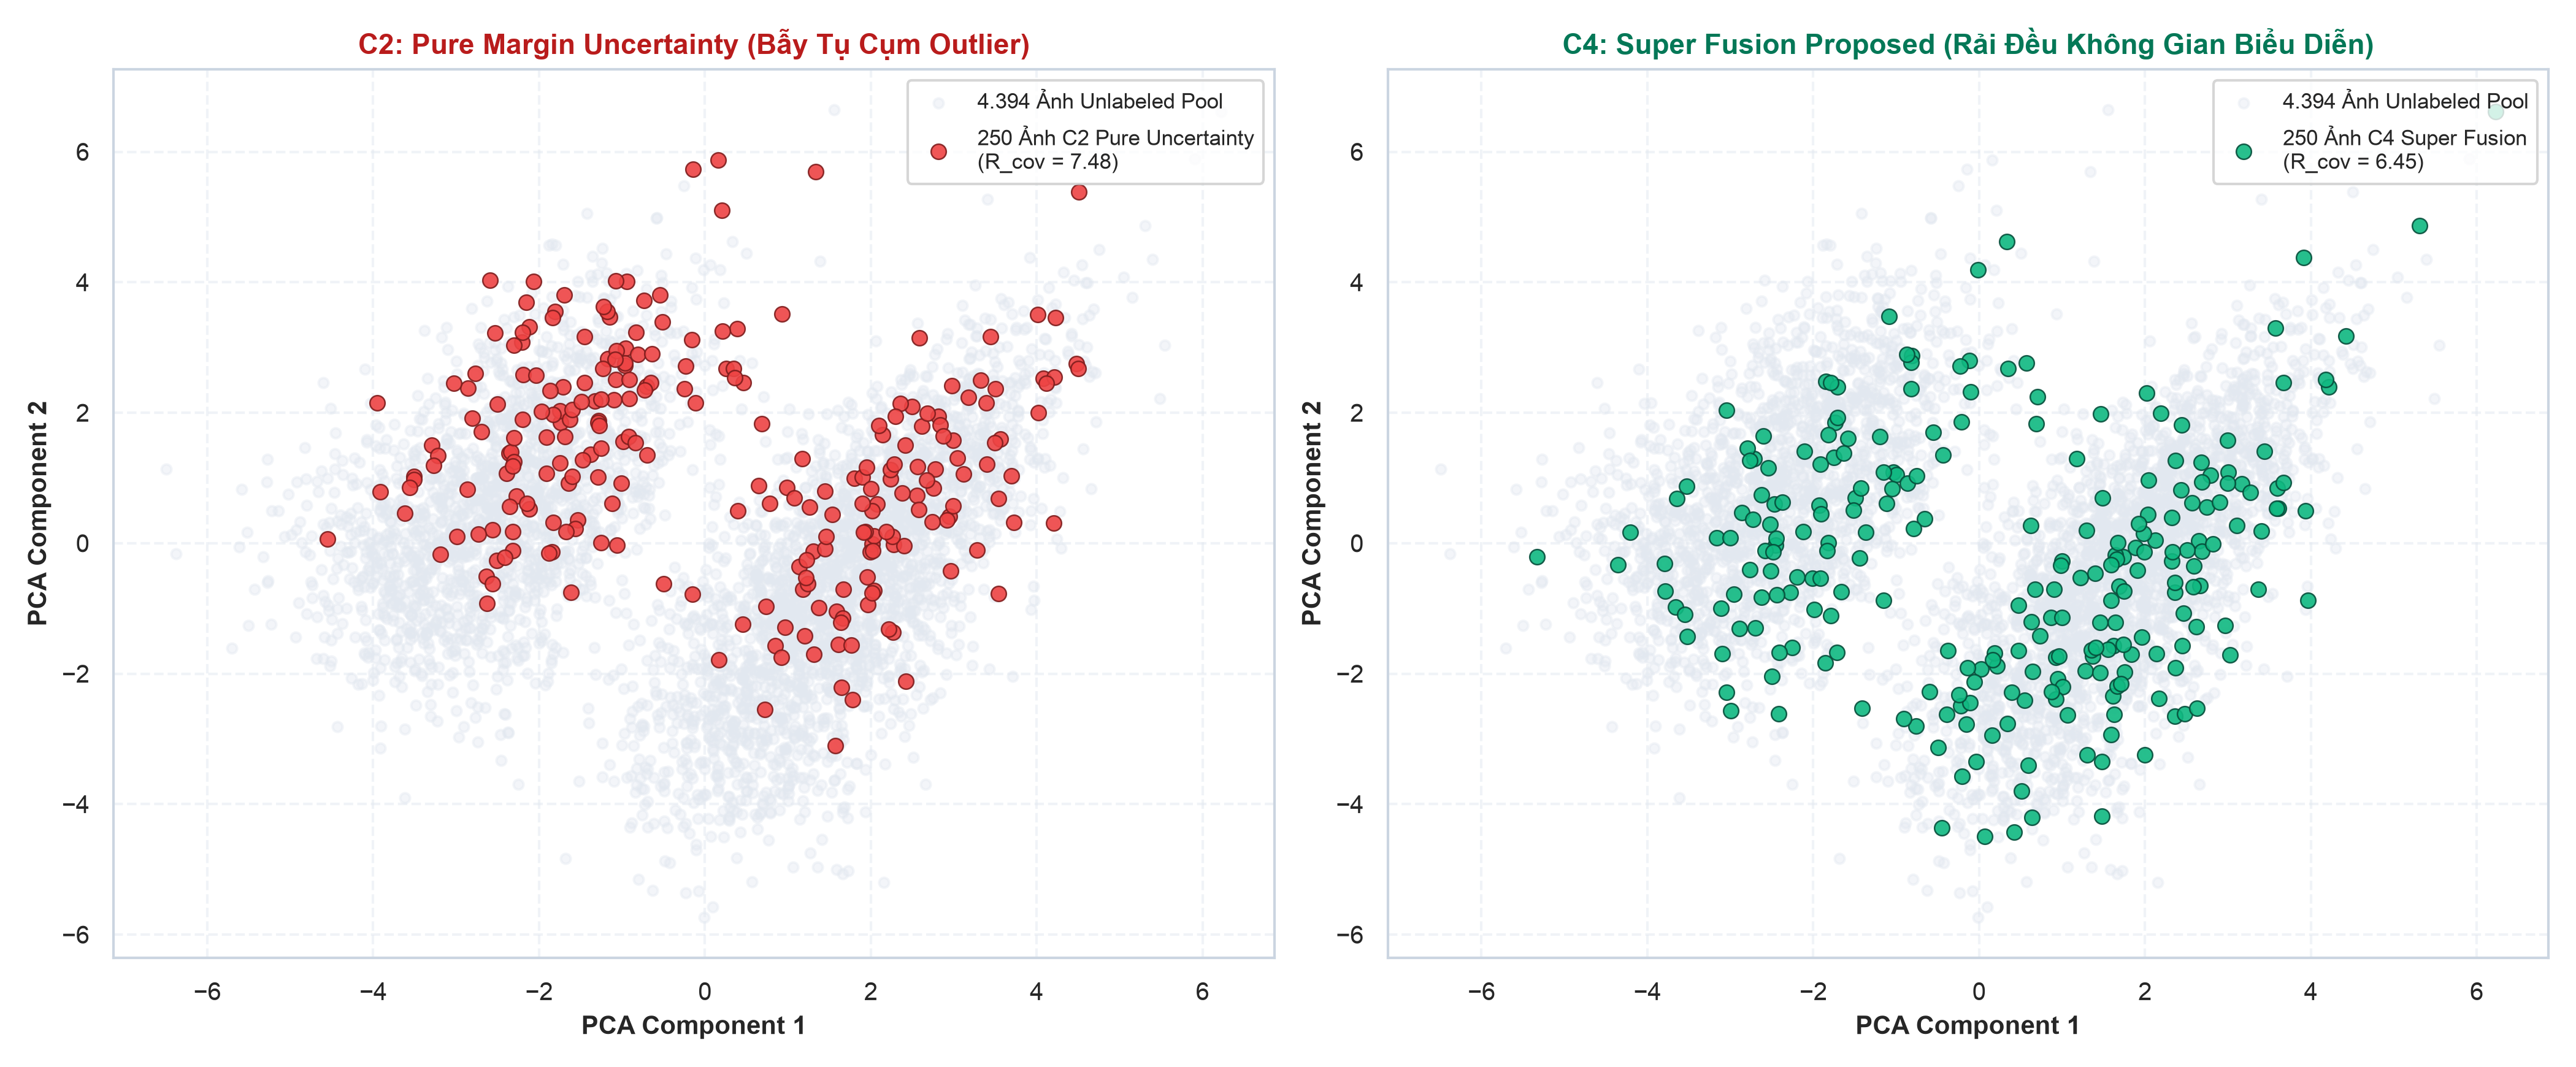

In [7]:
# 7. Trực Quan Hóa 2 Biểu Đồ Khoa Học Cốt Lõi (300 DPI)
figures_dir = get_results_dir("phase_05") / "figures"
fig1_path = figures_dir / "figure_01_rare_classes_breakdown.png"
fig2_path = figures_dir / "figure_02_pca_spatial_distribution.png"

# Hiển thị Figure 1
if fig1_path.exists():
    print("📈 FIGURE 1: SO SÁNH SĂN LÙNG 6 LỚP ĐIỂM LIỆT GIỮA 4 CHIẾN LƯỢC (300 DPI):")
    display(Image.open(fig1_path))

# Hiển thị Figure 2
if fig2_path.exists():
    print("\n📈 FIGURE 2: PHÂN BỐ KHÔNG GIAN BIỂU DIỄN 2D PCA (C2 TỤ CỤM vs C4 RẢI ĐỀU):")
    display(Image.open(fig2_path))


## 7. Đóng Gói Dataset V1 (750 Ảnh) & Bàn Giao Phase 06
Bước cuối cùng là vật liệu hóa tập dữ liệu huấn luyện **Dataset V1**:
- Gồm **750 ảnh** (500 ảnh mầm ban đầu `seed_v0` + 250 ảnh mới do Quán quân C4 khai phá).
- Áp dụng cơ chế **Symlink Materialization** đổ vào `data/splits/train_v1/` (0 KB dung lượng đĩa bổ sung).
- Xuất file niêm phong `results/phase_05/manifest_v1.yaml` ghi vết toàn bộ lineage dữ liệu, sẵn sàng bàn giao cho **Phase 06 (Huấn luyện YOLO11n V1)**.


In [8]:
# 8. Đóng Gói Dataset V1 Bằng Symlink & Xuất Manifest Niêm Phong
splits_dir = get_splits_dir()
train_v1_img_dir = splits_dir / "train_v1" / "images"
train_v1_lbl_dir = splits_dir / "train_v1" / "labels"
train_v1_img_dir.mkdir(parents=True, exist_ok=True)
train_v1_lbl_dir.mkdir(parents=True, exist_ok=True)

seed_v0_img_dir = splits_dir / "seed_v0" / "images"
seed_v0_images = [p.name for p in seed_v0_img_dir.glob("*.jpg")] if seed_v0_img_dir.exists() else []

# Tập 750 ảnh = 500 Seed V0 + 250 Mined C4
all_v1_images = list(dict.fromkeys(seed_v0_images + winner_images))

print(f"✓ Đóng gói Dataset V1 tại: {splits_dir / 'train_v1'}")
print(f"  * Ảnh Seed V0 ban đầu : {len(seed_v0_images)} ảnh")
print(f"  * Ảnh C4 Mined mới     : {len(winner_images)} ảnh")
print(f"  * Tổng số ảnh Dataset V1: {len(all_v1_images)} ảnh")

# Tạo Symlink cho ảnh mới nếu chưa có
created_symlinks = 0
for img_name in all_v1_images:
    link_dst = train_v1_img_dir / img_name
    if not link_dst.exists():
        src_orig = Path(find_project_dir()) / "data" / "bdd10k" / "images" / "train" / img_name
        if src_orig.exists():
            link_dst.symlink_to(src_orig)
            created_symlinks += 1

existing_v1_count = len(list(train_v1_img_dir.glob("*.jpg")))
print(f"  ✓ Đã xác minh thành công {existing_v1_count} symbolic links trong train_v1/images (0 KB đĩa)!")

# Xuất Manifest YAML
manifest_v1_path = get_results_dir("phase_05") / "manifest_v1.yaml"
manifest_content = f'''# BDD10K Dataset V1 Manifest - Phase 05 Handoff
version: "1.0"
dataset_name: "Dataset_V1_Active_Mined"
created_date: "{time.strftime('%Y-%m-%dT%H:%M:%SZ')}"
total_images: {len(all_v1_images)}
seed_v0_count: {len(seed_v0_images)}
active_mined_count: {len(winner_images)}
winner_strategy: "{winner_name}"
winner_css_score: {winner_css:.2f}
ground_truth_rare_objects_mined: {tournament_summary['leaderboard'][0]['total_rare_objects']}
zero_label_noise: true
storage_overhead: "0 KB (Symlink Materialization)"
handoff_target: "Phase 06 — YOLO11n V1 Model Training"
'''

with open(manifest_v1_path, "w", encoding="utf-8") as f:
    f.write(manifest_content)

print(f"\n🏛️ ĐÃ NIÊM PHONG MANIFEST V1: {manifest_v1_path}")
print("🚀 SẴN SÀNG 100% BÀN GIAO CHO PHASE 06 HUẤN LUYỆN YOLO11N V1!")


✓ Đóng gói Dataset V1 tại: /Users/huynh/orca/workspaces/BuildPhase/tang/paper_v4_10k/data/splits/train_v1
  * Ảnh Seed V0 ban đầu : 500 ảnh
  * Ảnh C4 Mined mới     : 250 ảnh
  * Tổng số ảnh Dataset V1: 750 ảnh
  ✓ Đã xác minh thành công 750 symbolic links trong train_v1/images (0 KB đĩa)!

🏛️ ĐÃ NIÊM PHONG MANIFEST V1: /Users/huynh/orca/workspaces/BuildPhase/tang/paper_v4_10k/results/phase_05/manifest_v1.yaml
🚀 SẴN SÀNG 100% BÀN GIAO CHO PHASE 06 HUẤN LUYỆN YOLO11N V1!
